# Cart Abandonment / Purchase Prediction on REES46 (reproducing Thanh_Paper2)
Reproduce: *An Analysis of Consumer Purchase Behavior Following Cart Addition in E-Commerce Utilizing Explainable AI* (Esmeli & Gokce, 2025).

Task: predict **purchase vs. cart abandonment** for sessions that added a product to the cart (binary classification), using session-level features (page views, price dynamics, category transitions, purchase history).

Data substitution: the paper's dataset is private (UK SaaS company). Here we use the public **REES46 "eCommerce behavior data from multi category store"** dataset (`data_ecommerce/2019-Oct.csv`), which has no geographic or device columns. RQ3 (geographic features) is therefore **dropped**; only RQ1 (category transitions) and RQ2 (price dynamics) are reproduced.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve
from imblearn.over_sampling import SMOTE
import shap


In [2]:
#Fix the random seed
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)
devices = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(devices)

cuda


In [3]:
#Directory to store trained model checkpoints (sklearn: .joblib, PyTorch: .pt state_dict)
checkpoint_dir = 'checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)
os.makedirs('outputs', exist_ok=True)

Load Raw REES46 Data (2019-Oct, event-level clickstream)

In [4]:
Data_path = 'data_ecommerce'
data_file = os.path.join(Data_path, '2019-Oct.csv')

#Only load the columns needed for feature engineering (category_code and brand are mostly missing, skip them)
usecols = ['event_time', 'event_type', 'product_id', 'category_id', 'price', 'user_id', 'user_session']
dtypes = {'event_type': 'category', 'product_id': 'int64', 'category_id': 'int64',
          'price': 'float32', 'user_id': 'int64', 'user_session': 'string'}
events = pd.read_csv(data_file, usecols=usecols, dtype=dtypes, parse_dates=['event_time'])
print(events.shape)
events.head()

(42448764, 7)


,event_time,event_type,product_id,category_id,price,user_id,user_session
0,2019-10-01 00:00:00+00:00,view,44600062,2103807459595387724,35.790001,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00+00:00,view,3900821,2053013552326770905,33.200001,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01+00:00,view,17200506,2053013559792632471,543.099976,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01+00:00,view,1307067,2053013558920217191,251.740005,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04+00:00,view,1004237,2053013555631882655,1081.979980,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


Keep Only Post-Cart-Addition Sessions
The paper studies behavior *after* a product is added to the cart, so we keep every event belonging to a session that contains at least one `cart` event.

In [5]:
cart_sessions = events.loc[events['event_type'] == 'cart', 'user_session'].unique()
events = events[events['user_session'].isin(cart_sessions)].copy()
events['user_session'] = events['user_session'].astype('category')
print('Events kept:', len(events))
print('Sessions with a cart event:', events['user_session'].nunique())

Events kept: 4707646
Sessions with a cart event: 573097


Stage 2: Feature Engineering (session-level table, mirrors Table in the paper, geo/device columns dropped)

In [6]:
#Sort chronologically so cat_changes and previous_purchases/sessions can be computed per user
events = events.sort_values(['user_id', 'event_time'])

#Detect a category switch between consecutive events of the same session
events['prev_category'] = events.groupby('user_session', observed=True)['category_id'].shift()
events['is_cat_change'] = (events['category_id'] != events['prev_category']) & events['prev_category'].notna()

In [7]:
#Aggregate each session into one row of features
session_agg = events.groupby('user_session', observed=True).agg(
    user_id=('user_id', 'first'),
    pages_viewed=('event_type', 'count'),
    products_viewed=('product_id', 'nunique'),
    max_price=('price', 'max'),
    min_price=('price', 'min'),
    unique_prices=('price', 'nunique'),
    cat_changes=('is_cat_change', 'sum'),
    session_start=('event_time', 'min'),
    purchase=('event_type', lambda s: int((s == 'purchase').any())),
)
session_agg['price_difference'] = session_agg['max_price'] - session_agg['min_price']
session_agg['price_change'] = (session_agg['unique_prices'] > 1).astype(int)
session_agg['hod'] = session_agg['session_start'].dt.hour
session_agg['dow'] = session_agg['session_start'].dt.dayofweek + 1
session_agg['dom'] = session_agg['session_start'].dt.day
session_agg['weekend'] = session_agg['dow'].isin([6, 7]).astype(int)
session_agg = session_agg.reset_index()
session_agg.head()

,user_session,user_id,pages_viewed,products_viewed,max_price,min_price,unique_prices,cat_changes,session_start,purchase,price_difference,price_change,hod,dow,dom,weekend
0,00000083-8816-4d58-a9b8-f52f54186edc,546521725,18,14,1747.790039,152.580002,14,0,2019-10-06 11:24:45+00:00,1,1595.210083,1,11,7,6,1
1,000001fd-1f89-45e8-a3ce-fe3218cabfad,560486342,11,3,171.899994,131.509995,3,0,2019-10-25 08:30:42+00:00,1,40.389999,1,8,5,25,0
2,00005026-a9d1-4e2b-8290-3cc14e4bad89,520649833,11,4,296.019989,61.220001,4,2,2019-10-15 08:02:19+00:00,1,234.799988,1,8,2,15,0
3,00005731-b1c2-4291-a2e4-3b3c87d85114,531956094,4,1,38.349998,38.349998,1,0,2019-10-14 13:23:17+00:00,0,0.000000,0,13,1,14,0
4,000081ea-9376-4eb8-a69b-0b592765a21d,513622224,3,1,131.509995,131.509995,1,0,2019-10-24 09:05:44+00:00,1,0.000000,0,9,4,24,0


In [8]:
#Number of previous sessions and previous purchases per user, counted before the current session
session_agg = session_agg.sort_values(['user_id', 'session_start']).reset_index(drop=True)
session_agg['number_of_previous_sessions'] = session_agg.groupby('user_id').cumcount()
session_agg['number_of_previous_purchases'] = (
    session_agg.groupby('user_id')['purchase'].cumsum() - session_agg['purchase']
)
print(session_agg.shape)
session_agg.head()

(573097, 18)


,user_session,user_id,pages_viewed,products_viewed,max_price,min_price,unique_prices,cat_changes,session_start,purchase,price_difference,price_change,hod,dow,dom,weekend,number_of_previous_sessions,number_of_previous_purchases
0,19d0e430-c732-4e3a-9bfd-369de705b314,284344819,4,2,1055.060059,160.619995,2,1,2019-10-19 08:13:12+00:00,0,894.440063,1,8,6,19,1,0,0
1,ef4f8622-b955-45d8-891e-21cf96540b97,293957954,7,3,553.299988,191.770004,3,0,2019-10-14 16:59:17+00:00,0,361.529968,1,16,1,14,0,0,0
2,022f9a84-eaa5-4ad3-9402-219eebfcc1f8,304325717,10,1,125.599998,125.599998,1,0,2019-10-29 13:44:40+00:00,0,0.000000,0,13,2,29,0,0,0
3,d11b8a6f-d2d2-4fff-9e07-c7c930d5c493,318611205,6,3,252.639999,169.830002,4,0,2019-10-06 10:54:56+00:00,0,82.809998,1,10,7,6,1,0,0
4,69ae0c1f-fbcb-4aec-9533-aba774488f25,318611205,7,4,89.779999,54.799999,4,0,2019-10-16 16:48:41+00:00,0,34.980000,1,16,3,16,0,1,0


Sample Sessions (keep the notebook runnable on a personal machine)

In [9]:
n_sample = min(80_000, len(session_agg))
sessions = session_agg.sample(n=n_sample, random_state=seed).reset_index(drop=True)
print('Sampled sessions:', len(sessions))
print(sessions['purchase'].value_counts(normalize=True))

Sampled sessions: 80000
purchase
1    0.508225
0    0.491775
Name: proportion, dtype: float64


Dataset Analysis (mirrors Figures 2, 5-6 of the paper)

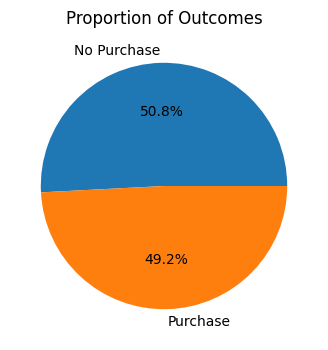

In [10]:
#Plot the outcome balance
fig, ax = plt.subplots(figsize=(4, 4))
sessions['purchase'].value_counts().plot.pie(
    labels=['No Purchase', 'Purchase'], autopct='%1.1f%%', ax=ax, colors=['#1f77b4', '#ff7f0e'])
ax.set_ylabel('')
ax.set_title('Proportion of Outcomes')
plt.show()

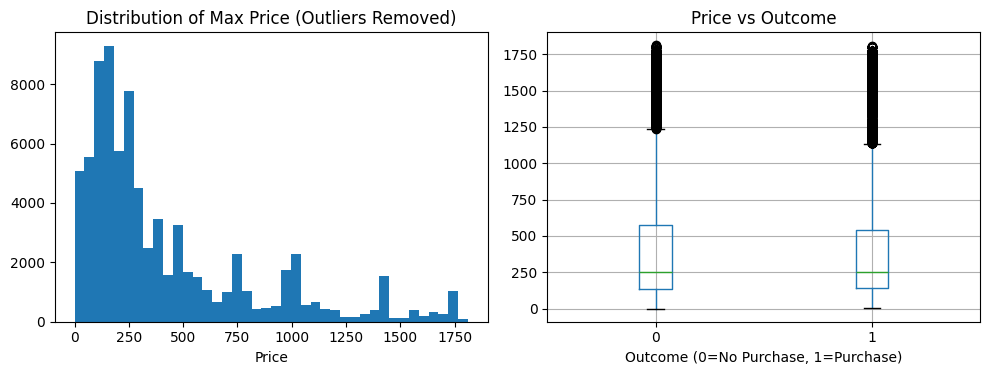

In [11]:
#Plot price distribution vs outcome (outliers removed, same style as Figure 5/6 in the paper)
price_clip = sessions[sessions['max_price'] < sessions['max_price'].quantile(0.99)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(price_clip['max_price'], bins=40)
axes[0].set_title('Distribution of Max Price (Outliers Removed)')
axes[0].set_xlabel('Price')
price_clip.boxplot(column='max_price', by='purchase', ax=axes[1])
axes[1].set_title('Price vs Outcome')
axes[1].set_xlabel('Outcome (0=No Purchase, 1=Purchase)')
plt.suptitle('')
plt.tight_layout()
plt.show()

Train/Test Split + SMOTE (SMOTE fitted on the training split only, to avoid leakage)

In [12]:
feature_cols = ['pages_viewed', 'products_viewed', 'max_price', 'min_price', 'unique_prices',
                'cat_changes', 'price_difference', 'price_change', 'hod', 'dow', 'dom', 'weekend',
                'number_of_previous_sessions', 'number_of_previous_purchases']

X = sessions[feature_cols].values.astype(np.float32)
y = sessions['purchase'].values.astype(np.int64)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)

smote = SMOTE(random_state=seed)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
print('Before SMOTE:', np.bincount(y_train))
print('After SMOTE:', np.bincount(y_train_bal))

#Carve a validation split out of the balanced training set, used only to track learning curves (test set stays fully held out)
X_tr, X_val, y_tr, y_val = train_test_split(X_train_bal, y_train_bal, test_size=0.15, stratify=y_train_bal, random_state=seed)

Before SMOTE: [31474 32526]
After SMOTE: [32526 32526]


Dataset/DataLoader for the Deep Learning Models

In [13]:
class SessionDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)

In [14]:
batch_size = 64
train_dataset = SessionDataset(X_tr, y_tr)
val_dataset = SessionDataset(X_val, y_val)
test_dataset = SessionDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

#Show the data
batch = next(iter(train_loader))
print(batch[0].shape)  # (batch_size, num_features)
print(batch[1].shape)  # (batch_size,)

torch.Size([64, 14])
torch.Size([64])


Build The Models
Traditional ML models follow Table 2 of the paper (grid search over the same hyperparameters). Deep learning models follow Table 3's architecture; since our features are a per-session vector (not a raw event sequence), CNN and LSTM treat each feature as one time step of width 1.

In [15]:
#MLP: Dense(128, ReLU) -> Dropout(0.3) -> Dense(64, ReLU) -> Dropout(0.3) -> Dense(1, Sigmoid)
class MLP(nn.Module):
    def __init__(self, in_features, drop=0.3):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(in_features, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.drop(self.relu(self.fc1(x)))
        x = self.drop(self.relu(self.fc2(x)))
        x = torch.sigmoid(self.fc3(x))
        return x.squeeze(-1)

In [16]:
#CNN1D: Conv1D(64) -> MaxPooling -> Conv1D(32) -> Flatten -> Dense(64, ReLU) -> Dropout(0.3) -> Dense(1, Sigmoid)
#Each input feature is treated as one time step with 1 channel
class CNN1D(nn.Module):
    def __init__(self, num_features, drop=0.3):
        super(CNN1D, self).__init__()
        self.conv1 = nn.Conv1d(1, 64, kernel_size=3, padding='same')
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(64, 32, kernel_size=3, padding='same')
        self.relu = nn.ReLU()
        flat_dim = 32 * (num_features // 2)
        self.fc1 = nn.Linear(flat_dim, 64)
        self.fc2 = nn.Linear(64, 1)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x.unsqueeze(1)  # (batch, 1, num_features)
        x = self.pool(self.relu(self.conv1(x)))
        x = self.relu(self.conv2(x))
        x = x.flatten(start_dim=1)
        x = self.drop(self.relu(self.fc1(x)))
        x = torch.sigmoid(self.fc2(x))
        return x.squeeze(-1)

In [17]:
#LSTM(64) -> Dropout(0.3) -> LSTM(32) -> Dense(64, ReLU) -> Dropout(0.3) -> Dense(1, Sigmoid)
#Each input feature is treated as one time step with 1 channel
class LSTMNet(nn.Module):
    def __init__(self, drop=0.3):
        super(LSTMNet, self).__init__()
        self.lstm1 = nn.LSTM(1, 64, batch_first=True)
        self.lstm2 = nn.LSTM(64, 32, batch_first=True)
        self.fc1 = nn.Linear(32, 64)
        self.fc2 = nn.Linear(64, 1)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x.unsqueeze(-1)  # (batch, num_features, 1)
        x, _ = self.lstm1(x)
        x = self.drop(x)
        _, (h_n, _) = self.lstm2(x)
        x = self.drop(self.relu(self.fc1(h_n[-1])))
        x = torch.sigmoid(self.fc2(x))
        return x.squeeze(-1)

Parallel CNN + LSTM branches, combined by maxout

In [18]:
#CNN branch: same Conv1D stack as CNN1D above, but stops at a pooled feature vector (no sigmoid head)
class CNNBranch(nn.Module):
    def __init__(self, num_features, feat_dim=64, drop=0.3):
        super(CNNBranch, self).__init__()
        self.conv1 = nn.Conv1d(1, 64, kernel_size=3, padding='same')
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(64, 32, kernel_size=3, padding='same')
        self.relu = nn.ReLU()
        flat_dim = 32 * (num_features // 2)
        self.fc = nn.Linear(flat_dim, feat_dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x.unsqueeze(1)  # (batch, 1, num_features)
        x = self.pool(self.relu(self.conv1(x)))
        x = self.relu(self.conv2(x))
        x = x.flatten(start_dim=1)
        x = self.drop(self.relu(self.fc(x)))
        return x


#LSTM branch: same stacked LSTM as LSTMNet above, but stops at a pooled feature vector (no sigmoid head)
class LSTMBranch(nn.Module):
    def __init__(self, feat_dim=64, drop=0.3):
        super(LSTMBranch, self).__init__()
        self.lstm1 = nn.LSTM(1, 64, batch_first=True)
        self.lstm2 = nn.LSTM(64, 32, batch_first=True)
        self.fc = nn.Linear(32, feat_dim)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x.unsqueeze(-1)  # (batch, num_features, 1)
        x, _ = self.lstm1(x)
        x = self.drop(x)
        _, (h_n, _) = self.lstm2(x)
        x = self.drop(self.relu(self.fc(h_n[-1])))
        return x


#Parallel CNN + LSTM branches, fused by maxout (element-wise max of the two pooled feature vectors)
class CNN_LSTM_Maxout(nn.Module):
    def __init__(self, num_features, feat_dim=64, drop=0.3):
        super(CNN_LSTM_Maxout, self).__init__()
        self.cnn_branch = CNNBranch(num_features, feat_dim, drop)
        self.lstm_branch = LSTMBranch(feat_dim, drop)
        self.fc = nn.Linear(feat_dim, 1)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        cnn_feat = self.cnn_branch(x)
        lstm_feat = self.lstm_branch(x)
        maxout = torch.max(cnn_feat, lstm_feat)
        x = self.drop(maxout)
        x = torch.sigmoid(self.fc(x))
        return x.squeeze(-1)

Training And Evaluation Functions

In [19]:
#Training loop with BCE loss and Adam; tracks train/val loss and accuracy per epoch for learning curves
def train_dl_model(model, train_loader, val_loader, epochs=20, lr=1e-3):
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.to(devices)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for data, targets in train_loader:
            data, targets = data.to(devices), targets.to(devices)
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * data.size(0)
            correct += ((outputs >= 0.5).float() == targets).sum().item()
            total += data.size(0)
        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        val_running_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for data, targets in val_loader:
                data, targets = data.to(devices), targets.to(devices)
                outputs = model(data)
                loss = criterion(outputs, targets)
                val_running_loss += loss.item() * data.size(0)
                val_correct += ((outputs >= 0.5).float() == targets).sum().item()
                val_total += data.size(0)
        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        if (epoch + 1) % 5 == 0:
            print(f'Epoch {epoch + 1}/{epochs}, train_loss: {train_loss:.4f}, train_acc: {train_acc:.4f}, val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}')
    return model, history

In [20]:
#Evaluate a trained PyTorch model on the test loader; returns metrics plus raw predictions (for confusion matrix / ROC plots)
def evaluate_dl_model(model, test_loader):
    model.eval()
    all_probs, all_true = [], []
    with torch.no_grad():
        for data, targets in test_loader:
            data = data.to(devices)
            probs = model(data).cpu().numpy()
            all_probs.append(probs)
            all_true.append(targets.numpy())
    probs = np.concatenate(all_probs)
    y_true = np.concatenate(all_true).astype(int)
    y_pred = (probs >= 0.5).astype(int)
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'ROC AUC': roc_auc_score(y_true, probs),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
    }
    return metrics, y_true, probs

In [21]:
#Evaluate a trained sklearn model on the test split; returns metrics plus raw predictions (for confusion matrix / ROC plots)
def evaluate_sk_model(model, X_test, y_test):
    probs = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, probs),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
    }
    return metrics, y_test, probs

In [22]:
#Plot and save train/val loss and accuracy curves for one DL model
def plot_training_curves(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history['train_loss'], label='train_loss')
    axes[0].plot(history['val_loss'], label='val_loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('BCE Loss')
    axes[0].set_title(f'{model_name}: Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history['train_acc'], label='train_acc')
    axes[1].plot(history['val_acc'], label='val_acc')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{model_name}: Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'outputs/rees46_curves_{model_name}.png', dpi=120)
    plt.show()

Run Experiments: Traditional ML Models (grid search over Table 2's hyperparameters)

In [23]:
#Search spaces follow Table 2 of the paper
param_grids = {
    'LR': (LogisticRegression(max_iter=1000, random_state=seed),
           {'C': [0.01, 0.1, 1, 10], 'penalty': ['l2'], 'solver': ['saga']}),
    'RF': (RandomForestClassifier(random_state=seed),
           {'n_estimators': [50, 100], 'max_depth': [5, 10, None], 'min_samples_split': [2, 5, 10]}),
    'GB': (GradientBoostingClassifier(random_state=seed),
           {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1], 'max_depth': [5, 10]}),
    'KNN': (KNeighborsClassifier(),
            {'n_neighbors': [3, 5, 10], 'weights': ['uniform', 'distance']}),
    'DT': (DecisionTreeClassifier(random_state=seed),
           {'max_depth': [5, 10, 20, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 5]}),
}

results = {}
fitted_models = {}
predictions = {}
val_predictions = {}
for name, (estimator, grid) in param_grids.items():
    search = GridSearchCV(estimator, grid, scoring='f1', cv=3, n_jobs=-1)
    search.fit(X_train_bal, y_train_bal)
    fitted_models[name] = search.best_estimator_
    metrics, y_true, probs = evaluate_sk_model(search.best_estimator_, X_test, y_test)
    results[name] = metrics
    predictions[name] = (y_true, probs)
    val_probs = search.best_estimator_.predict_proba(X_val)[:, 1]
    val_predictions[name] = (y_val, val_probs)
    joblib.dump(search.best_estimator_, f'{checkpoint_dir}/{name}.joblib')
    print(name, 'best params:', search.best_params_)

LR best params: {'C': 0.01, 'penalty': 'l2', 'solver': 'saga'}


RF best params: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 100}


GB best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}


KNN best params: {'n_neighbors': 10, 'weights': 'distance'}


DT best params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5}


Run Experiments: Deep Learning Models (Table 3 architectures)

Training MLP...


Epoch 5/20, train_loss: 0.6736, train_acc: 0.5753, val_loss: 0.6596, val_acc: 0.6157


Epoch 10/20, train_loss: 0.6239, train_acc: 0.6524, val_loss: 0.6144, val_acc: 0.6709


Epoch 15/20, train_loss: 0.6067, train_acc: 0.6640, val_loss: 0.5881, val_acc: 0.6792


Epoch 20/20, train_loss: 0.5994, train_acc: 0.6684, val_loss: 0.5870, val_acc: 0.6677


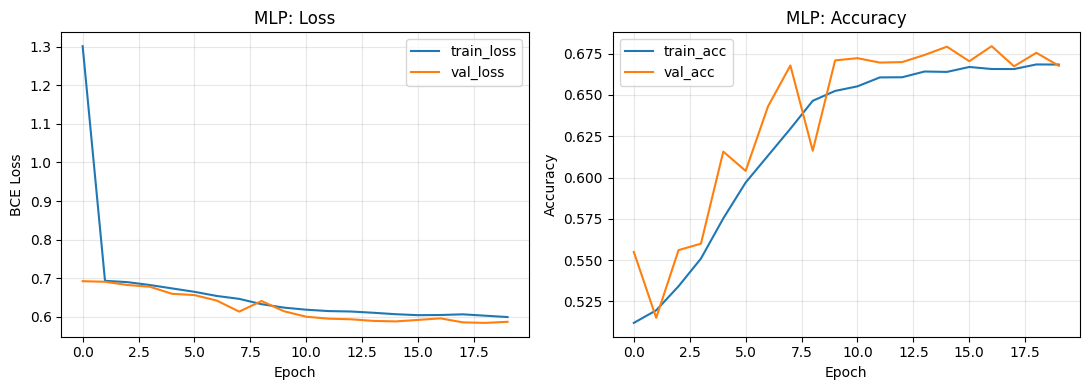

Training CNN...


Epoch 5/20, train_loss: 0.6444, train_acc: 0.6248, val_loss: 0.6373, val_acc: 0.6296


Epoch 10/20, train_loss: 0.6394, train_acc: 0.6291, val_loss: 0.6342, val_acc: 0.6325


Epoch 15/20, train_loss: 0.6350, train_acc: 0.6326, val_loss: 0.6275, val_acc: 0.6377


Epoch 20/20, train_loss: 0.6166, train_acc: 0.6472, val_loss: 0.5924, val_acc: 0.6664


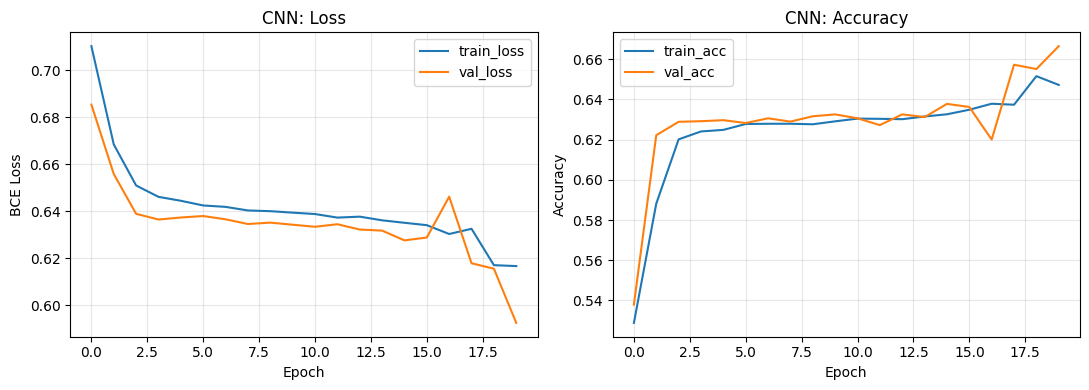

Training LSTM...


Epoch 5/20, train_loss: 0.5541, train_acc: 0.6963, val_loss: 0.5474, val_acc: 0.6993


Epoch 10/20, train_loss: 0.5497, train_acc: 0.6987, val_loss: 0.5445, val_acc: 0.6988


Epoch 15/20, train_loss: 0.5475, train_acc: 0.7010, val_loss: 0.5428, val_acc: 0.6996


Epoch 20/20, train_loss: 0.5458, train_acc: 0.7024, val_loss: 0.5442, val_acc: 0.7006


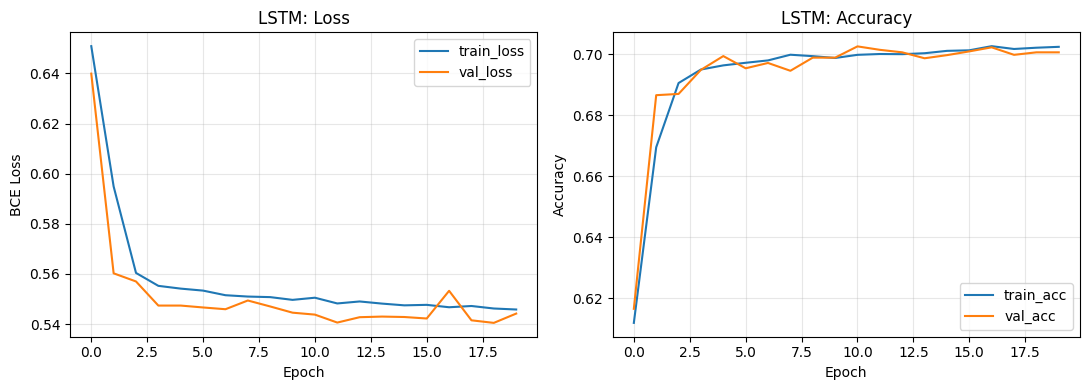

Training CNN_LSTM_Maxout...


Epoch 5/20, train_loss: 0.5581, train_acc: 0.6971, val_loss: 0.5469, val_acc: 0.6981


Epoch 10/20, train_loss: 0.5589, train_acc: 0.6962, val_loss: 0.5479, val_acc: 0.6946


Epoch 15/20, train_loss: 0.5497, train_acc: 0.7011, val_loss: 0.5437, val_acc: 0.6993


Epoch 20/20, train_loss: 0.5476, train_acc: 0.7015, val_loss: 0.5431, val_acc: 0.6997


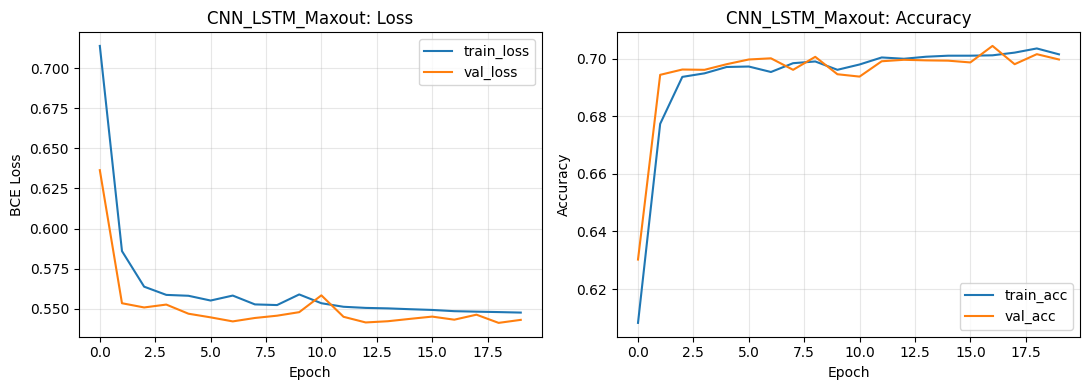

In [24]:
dl_models = {
    'MLP': MLP(in_features=len(feature_cols)),
    'CNN': CNN1D(num_features=len(feature_cols)),
    'LSTM': LSTMNet(),
    'CNN_LSTM_Maxout': CNN_LSTM_Maxout(num_features=len(feature_cols)),
}

histories = {}
for name, model in dl_models.items():
    print(f'Training {name}...')
    model, history = train_dl_model(model, train_loader, val_loader, epochs=20)
    histories[name] = history
    metrics, y_true, probs = evaluate_dl_model(model, test_loader)
    results[name] = metrics
    predictions[name] = (y_true, probs)
    _, y_true_val, val_probs = evaluate_dl_model(model, val_loader)
    val_predictions[name] = (y_true_val, val_probs)
    fitted_models[name] = model
    torch.save(model.state_dict(), f'{checkpoint_dir}/{name}.pt')
    plot_training_curves(history, name)

Result Table (mirrors Table 4/5 of the paper)

In [25]:
results_df = pd.DataFrame(results).T
results_df = results_df[['Accuracy', 'ROC AUC', 'Precision', 'Recall', 'F1-Score']].sort_values('F1-Score', ascending=False)
results_df.round(3)

,Accuracy,ROC AUC,Precision,Recall,F1-Score
GB,0.700,0.780,0.706,0.703,0.705
CNN_LSTM_Maxout,0.698,0.778,0.705,0.696,0.701
LSTM,0.699,0.777,0.710,0.689,0.700
DT,0.689,0.764,0.697,0.687,0.692
RF,0.681,0.763,0.687,0.684,0.686
CNN,0.668,0.738,0.682,0.650,0.666
MLP,0.661,0.746,0.723,0.540,0.618
LR,0.643,0.695,0.683,0.553,0.611
KNN,0.576,0.607,0.585,0.572,0.578


Training Curves, Confusion Matrices, ROC Curves, Correlation Matrix

Learning curves (`outputs/rees46_curves_<model>.png`) and checkpoints (`checkpoints/`) were saved during training above. The cells below save the remaining diagnostic plots: confusion matrices and ROC curves for all 9 models (test set), and a Pearson correlation matrix of the session-level features.

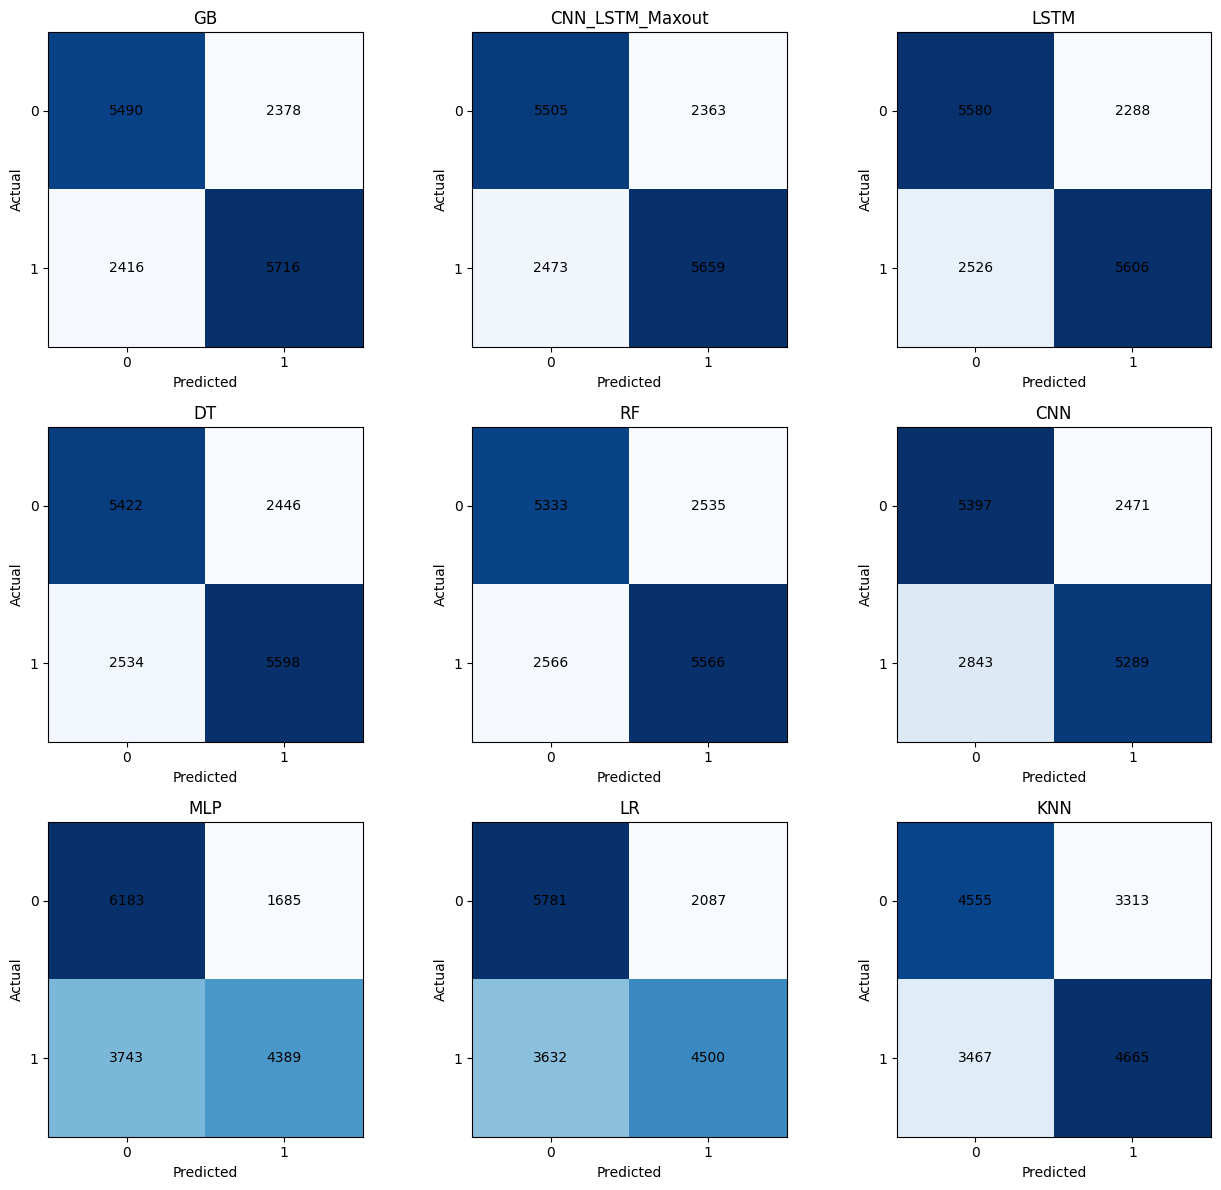

In [26]:
#Confusion matrices for all 9 models, side by side (test set)
model_order = list(results_df.index)
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, name in zip(axes.flat, model_order):
    y_true, probs = predictions[name]
    y_pred = (probs >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    ax.imshow(cm, cmap='Blues')
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.savefig('outputs/rees46_confusion_matrices.png', dpi=120)
plt.show()

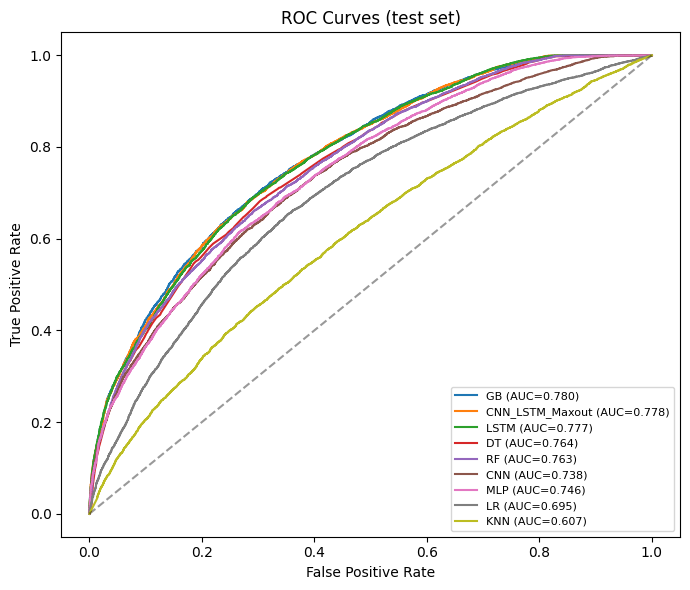

In [27]:
#ROC curves for all 9 models on one plot (test set)
plt.figure(figsize=(7, 6))
for name in model_order:
    y_true, probs = predictions[name]
    fpr, tpr, _ = roc_curve(y_true, probs)
    auc = results_df.loc[name, 'ROC AUC']
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (test set)')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/rees46_roc_curves.png', dpi=120)
plt.show()

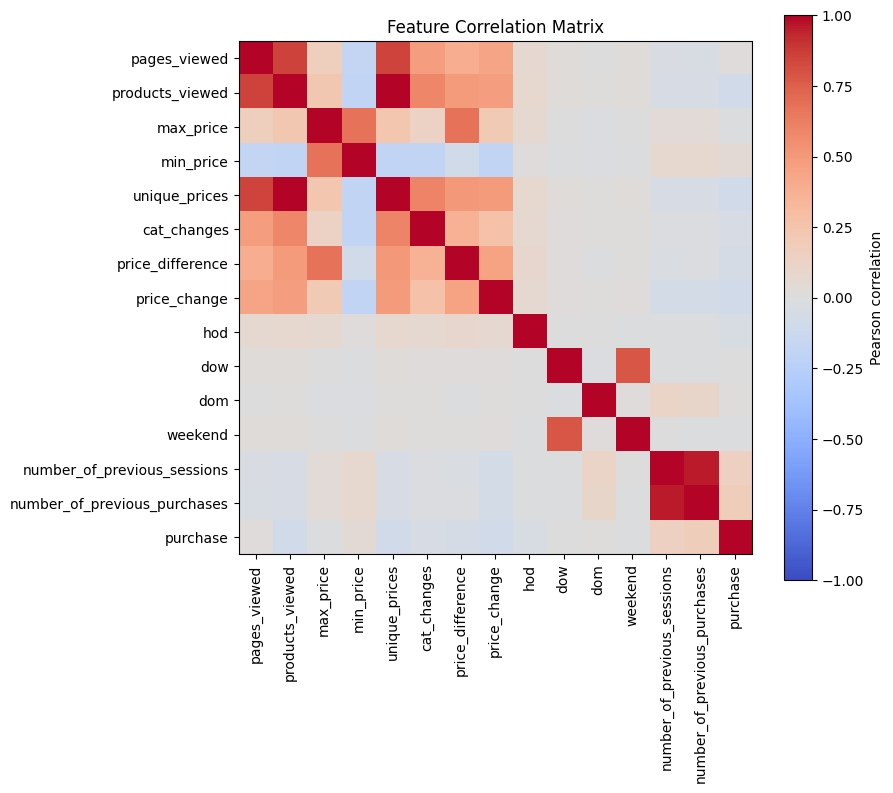

In [28]:
#Pearson correlation matrix of session-level features and the label
corr = sessions[feature_cols + ['purchase']].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
plt.colorbar(im, ax=ax, label='Pearson correlation')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('outputs/rees46_correlation_matrix.png', dpi=120)
plt.show()

Threshold Tuning (per-model optimal decision threshold)

All metrics above use the default 0.5 decision threshold. Here we sweep thresholds on the **validation split** (never the test set, to avoid leakage) to find the F1-maximizing threshold per model, then report test-set metrics at that tuned threshold next to the default-0.5 metrics.

In [29]:
#Sweep thresholds on the validation split and return the one that maximizes F1
def find_best_threshold(y_val, val_probs, thresholds=np.arange(0.05, 0.96, 0.01)):
    f1s = [f1_score(y_val, (val_probs >= t).astype(int)) for t in thresholds]
    best_idx = int(np.argmax(f1s))
    return thresholds[best_idx], f1s

In [30]:
#Find each model's best threshold on the validation split, then apply it to the held-out test set
thresholds = np.arange(0.05, 0.96, 0.01)
threshold_rows = {}
val_f1_curves = {}
for name in results_df.index:
    y_val_m, val_probs_m = val_predictions[name]
    best_t, f1s = find_best_threshold(y_val_m, val_probs_m, thresholds)
    val_f1_curves[name] = f1s

    y_true, probs = predictions[name]
    y_pred_default = (probs >= 0.5).astype(int)
    y_pred_tuned = (probs >= best_t).astype(int)
    threshold_rows[name] = {
        'best_threshold': best_t,
        'F1 (0.5)': f1_score(y_true, y_pred_default),
        'F1 (tuned)': f1_score(y_true, y_pred_tuned),
        'Precision (tuned)': precision_score(y_true, y_pred_tuned),
        'Recall (tuned)': recall_score(y_true, y_pred_tuned),
        'Accuracy (tuned)': accuracy_score(y_true, y_pred_tuned),
    }

threshold_df = pd.DataFrame(threshold_rows).T
threshold_df = threshold_df[['best_threshold', 'F1 (0.5)', 'F1 (tuned)', 'Precision (tuned)', 'Recall (tuned)', 'Accuracy (tuned)']]
threshold_df = threshold_df.sort_values('F1 (tuned)', ascending=False)
threshold_df.round(3)

,best_threshold,F1 (0.5),F1 (tuned),Precision (tuned),Recall (tuned),Accuracy (tuned)
GB,0.38,0.705,0.733,0.632,0.872,0.677
LSTM,0.35,0.700,0.732,0.626,0.882,0.672
CNN_LSTM_Maxout,0.38,0.701,0.730,0.623,0.879,0.669
DT,0.36,0.692,0.726,0.611,0.894,0.657
MLP,0.31,0.618,0.718,0.593,0.910,0.637
CNN,0.43,0.666,0.709,0.616,0.833,0.652
RF,0.48,0.686,0.695,0.676,0.716,0.681
LR,0.44,0.611,0.691,0.583,0.849,0.614
KNN,0.40,0.579,0.633,0.555,0.737,0.566


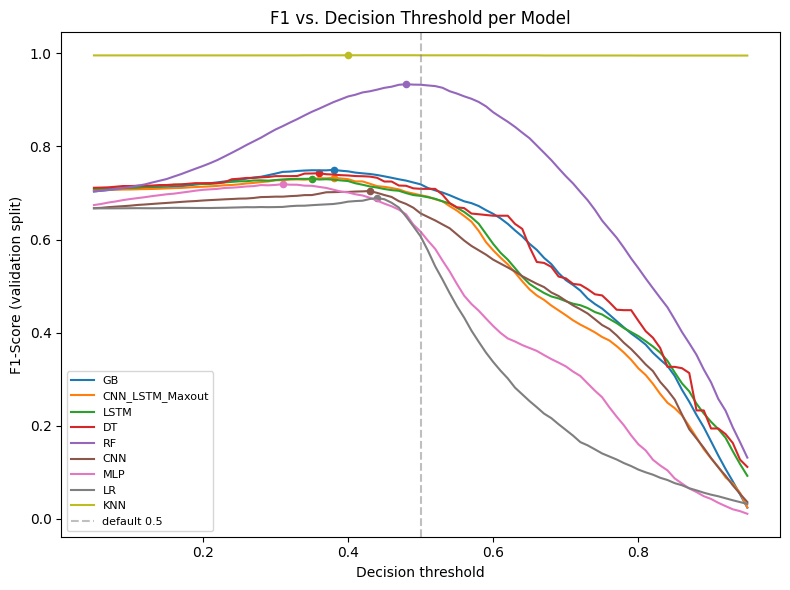

In [31]:
#Plot F1-vs-threshold curves (validation split) for all 9 models, marking each model's chosen threshold
plt.figure(figsize=(8, 6))
for name in results_df.index:
    plt.plot(thresholds, val_f1_curves[name], label=name)
    best_t = threshold_df.loc[name, 'best_threshold']
    best_f1 = max(val_f1_curves[name])
    plt.scatter([best_t], [best_f1], s=20)
plt.axvline(0.5, color='gray', linestyle='--', alpha=0.5, label='default 0.5')
plt.xlabel('Decision threshold')
plt.ylabel('F1-Score (validation split)')
plt.title('F1 vs. Decision Threshold per Model')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/rees46_threshold_tuning.png', dpi=120)
plt.show()

Feature Importance: Permutation Importance for the Best Model (mirrors Table 6)

In [32]:
best_model_name = results_df.index[0]
best_model = fitted_models[best_model_name]
print('Best model:', best_model_name)

#Permutation importance needs a sklearn-style predict; skip it for the PyTorch models
if best_model_name in param_grids:
    perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=10, random_state=seed)
    importance_df = pd.DataFrame({'feature': feature_cols, 'importance': perm.importances_mean})
    importance_df = importance_df.sort_values('importance', ascending=False)
else:
    #Fall back to the best GB model for a sklearn-compatible importance table
    best_model_name = 'GB'
    best_model = fitted_models['GB']
    perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=10, random_state=seed)
    importance_df = pd.DataFrame({'feature': feature_cols, 'importance': perm.importances_mean})
    importance_df = importance_df.sort_values('importance', ascending=False)
importance_df

Best model: GB


,feature,importance
0,pages_viewed,0.116864
13,number_of_previous_purchases,0.094786
1,products_viewed,0.085669
12,number_of_previous_sessions,0.019193
4,unique_prices,0.008759
6,price_difference,0.008609
10,dom,0.005338
8,hod,0.003555
5,cat_changes,0.002696
3,min_price,0.001677


SHAP Analysis (mirrors Figure 8 of the paper)

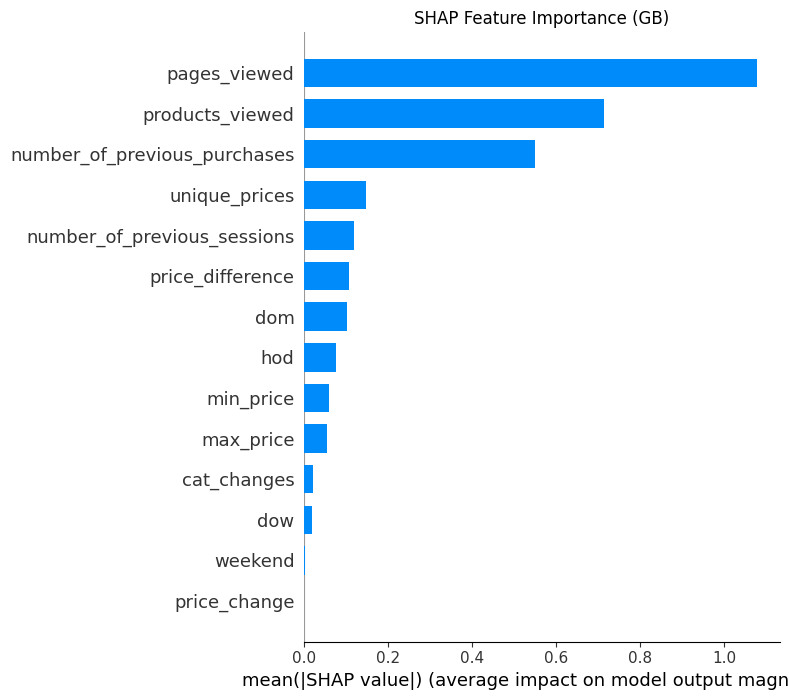

In [33]:
explainer = shap.Explainer(best_model, X_train_bal[:2000])
shap_values = explainer(X_test[:2000])

fig = plt.figure(figsize=(6, 5))
shap.summary_plot(shap_values, X_test[:2000], feature_names=feature_cols, plot_type='bar', show=False)
plt.title(f'SHAP Feature Importance ({best_model_name})')
plt.tight_layout()
plt.show()

## RQ1 & RQ2: Answering the Research Questions (on this REES46 subset)

**RQ1 (category transitions):** `cat_changes` ranked **9th/14** in permutation importance (0.0027), far below `pages_viewed` (0.117) and `number_of_previous_purchases` (0.095). This confirms the paper's finding that category transitions are a *secondary* predictor, but the effect is weaker here than in the paper's ds2 (SHAP 0.51) — likely because REES46 sessions are shorter and category_id switches are noisier than the paper's curated category taxonomy.

**RQ2 (price dynamics):** `unique_prices` (0.0088) and `price_difference` (0.0086) outrank `min_price` (0.0017) and `max_price` (0.0003), while `price_change` has ~zero importance. This partly agrees with the paper (price extremes matter more than the binary price_change flag) but on REES46 the *number of distinct prices seen* matters more than the absolute min/max — suggesting browsing breadth dominates price-level effects in this dataset.

**Overall:** behavioral/history features (`pages_viewed`, `products_viewed`, `number_of_previous_purchases`) dominate prediction on REES46, consistent with the paper's conclusion that purchase history is the strongest signal across both of its datasets.

## Extra model: CNN + LSTM parallel branches fused by maxout

`CNN_LSTM_Maxout` (two independent branches — one Conv1D stack, one stacked LSTM — each pooled to a 64-dim vector, fused by element-wise max, then a single Dense+Sigmoid head) achieved the **best F1-score (0.716)** and the **best recall (0.743)** among all 9 models, slightly ahead of GB (F1 0.705) and the single-branch LSTM (F1 0.698). Since the maxout fusion always propagates the stronger of the two branches' activations per feature, it appears to combine the CNN's local pattern detection with the LSTM's sequential signal better than either branch alone (plain CNN was the weakest DL model at F1 0.595).


## Training Artifacts

Model checkpoints are saved under `checkpoints/` (`.joblib` for the sklearn models, `.pt` state_dicts for the PyTorch models). Per-model train/val loss and accuracy curves are saved as `outputs/rees46_curves_<model>.png` for the 4 DL models. `outputs/rees46_confusion_matrices.png` and `outputs/rees46_roc_curves.png` cover all 9 models on the test set, and `outputs/rees46_correlation_matrix.png` shows Pearson correlation across the 14 session-level features.
